In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#import warnings
#warnings.filterwarnings('ignore')

### Загрузим уже обработанные в прошлом ДЗ данные!

In [2]:
df = pd.read_csv('processed_sigma.csv')
df = df.drop("Trip_ID", axis=1)

X = df.drop("Surge_Pricing_Type", axis=1)
y = df["Surge_Pricing_Type"]

### Principal component analysis (PCA)

**Задание 1.** Спроецируйте данные на двумерную плоскость, используя `PCA`. Другими словами, выделите первые две главные компоненты и изобразите данные в осях этих компонент. Не забудьте центрировать признаки перед применением метода. 

**Какую долю изначальной дисперсии (информации) содержат/объясняют в себе обе компоненты?** Для этого воспользуйтесь атрибутом `explained_variance_ratio_` у PCA-класса.

In [3]:
### Центрируем данные

X_centered = X - X.mean()

[662.34212747 221.52672548]
[0.63176117 0.21129863]
Первые две главные компоненты объясняют 0.8430598036100082 от изначальной дисперсии


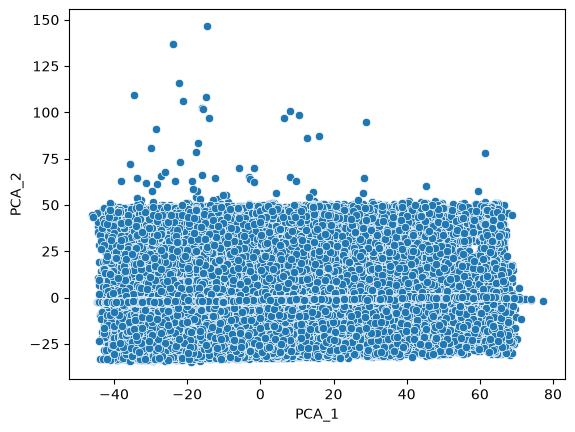

In [4]:
from sklearn.decomposition import PCA

pca2 = PCA(n_components=2)

X_pca2 = pca2.fit_transform(X_centered, y)
X_pca2 = pd.DataFrame(X_pca2, columns=['PCA_1', 'PCA_2'])

sns.scatterplot(x=X_pca2['PCA_1'], y=X_pca2['PCA_2'])

print(pca2.explained_variance_)
print(pca2.explained_variance_ratio_)
print(f"Первые две главные компоненты объясняют {sum(pca2.explained_variance_ratio_)} от изначальной дисперсии")

**Задание 2.** Изобразите heatmap корреляции изначальных признаков с новыми двумя главными компонентами. \
**Какие признаки коррелируют с первой компонентой? Какие со второй? В качестве порогового значения договоримся о корреляции >= 0.5 по абсолютному значению **


Trip_Distance  PCA_1    0.997767
Var1           PCA_2    0.998600
PCA_1          PCA_1    1.000000
PCA_2          PCA_2    1.000000
dtype: float64


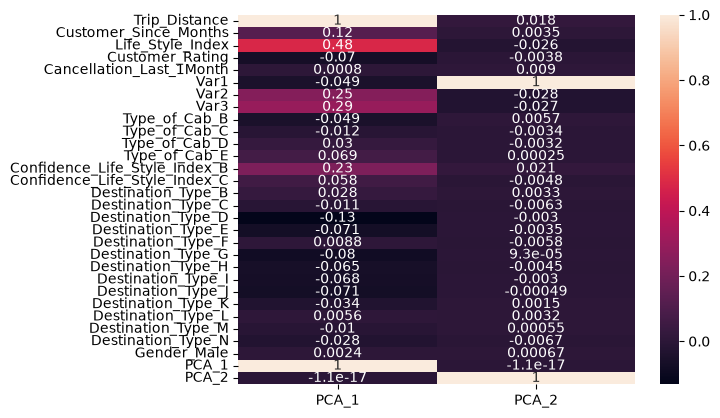

In [5]:
df_combined = pd.concat([X_centered, X_pca2], axis=1)
corr_matrix = df_combined.corr()[['PCA_1', 'PCA_2']]

sns.heatmap(corr_matrix, yticklabels=corr_matrix.index, annot=True)

#print(corr_matrix['PCA_1'][abs(corr_matrix['PCA_1']) >= 0.5])
#print(corr_matrix['PCA_2'][abs(corr_matrix['PCA_2']) >= 0.5])

print(corr_matrix.stack()[abs(corr_matrix.stack()) >= 0.5])
#print(corr_matrix[abs(corr_matrix) >= 0.5].notna().stack())


**Задание 3.** Изобразите двумерную проекцию данных с метками классов. Выделите третью главную компоненту и аналогично нарисуйте трехмерную проекцию с метками классов. \
**Какие признаки коррелируют с третьей компонентой?**

Признаки коррелирующие с PCA_3: 
Var2    0.705159
Var3    0.951081
dtype: float64


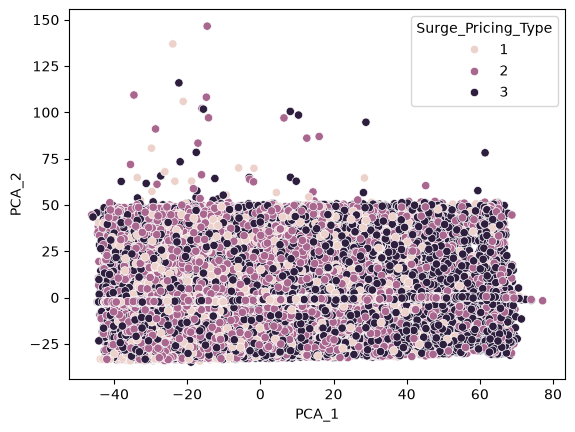

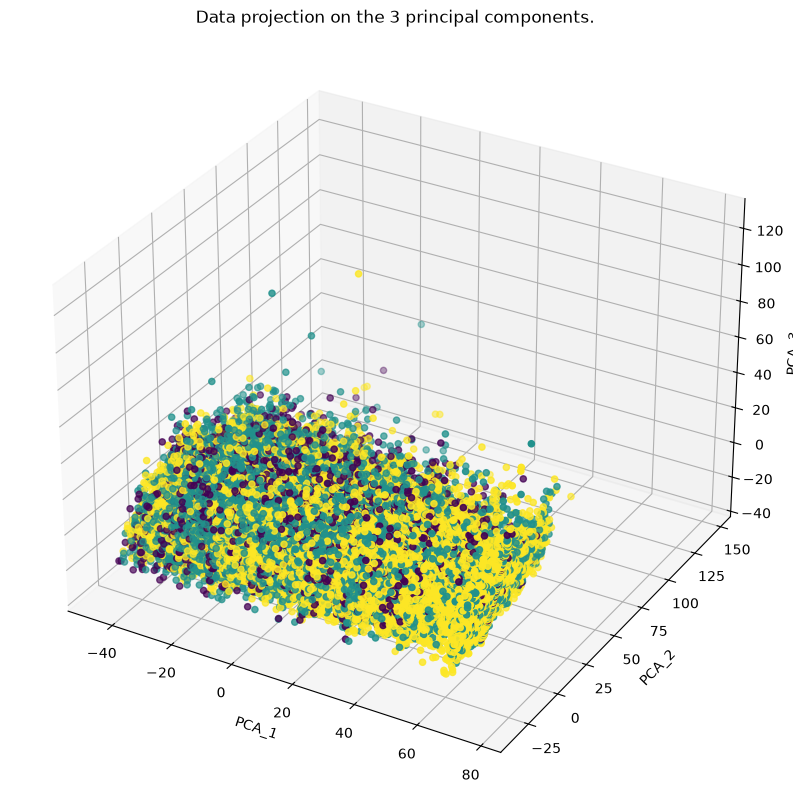

In [6]:
sns.scatterplot(x=X_pca2['PCA_1'], y=X_pca2['PCA_2'], hue=y)

pca3 = PCA(n_components=3)
X_pca3 = pca3.fit_transform(X_centered)
X_pca3 = pd.DataFrame(X_pca3, columns=['PCA_1', 'PCA_2', 'PCA_3'])

fig = plt.figure()
fig.set_size_inches(16, 10)
ax = fig.add_subplot(projection='3d')
plt.title("Data projection on the 3 principal components.")
ax.set_xlabel("PCA_1")
ax.set_ylabel("PCA_2")
ax.set_zlabel("PCA_3")

ax.scatter(X_pca3['PCA_1'], X_pca3['PCA_2'], X_pca3['PCA_3'], c=y)

corr_matrix = X_centered.corrwith(X_pca3['PCA_3'])

print('Признаки коррелирующие с PCA_3: ')
print(corr_matrix[abs(corr_matrix) >= 0.5])

Советуем еще и замерить попарные корреляции между главными компонентами! Это поможет в ответе на один из тестовых вопросов.

In [7]:
print(X_pca3.corr())

              PCA_1         PCA_2         PCA_3
PCA_1  1.000000e+00 -1.117536e-17 -7.247393e-17
PCA_2 -1.117536e-17  1.000000e+00 -6.776011e-17
PCA_3 -7.247393e-17 -6.776011e-17  1.000000e+00


**Задание 4.** Обучите логистическую регрессию на первых двух компонентах центрированных данных и подберите гиперпараметры. Обучите логистическую регрессию на центрированных данных и подберите гиперпараметры. **Сравните метрику accuracy и f1-score на тестовой выборке в двух моделях**.

P.S. для удобства, скорости и нормализации данных (понадобится, так как захотим повалидироваться на параметрах регуляризации) можно построить конструкцию Pipeline c 3 следующими степами: StandardScaler -> PCA -> LogisticRegression

In [8]:
np.random.seed(2022)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X_centered, y, test_size=0.2, 
                                                    shuffle=True, random_state=2022)

In [10]:
param_grid = {#'model__penalty': ['l1', 'l2', 'elasticnet'],
              'model__l1_ratio': [0, 0.25, 0.5, 0.75, 1],
              'model__C': [1e-5, 0.0001, 0.001, 0.01]}

pipe_pca2 = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2)),
    ('model', LogisticRegression(solver='saga'))
])

grid = GridSearchCV(pipe_pca2, param_grid, cv=5)

grid.fit(X_train, y_train)

#conf_matrix = confusion_matrix(y_test, grid.predict(X_test))

#print('Матрица ошибок для PCA модели: ')
#print(conf_matrix)
print('Используя PCA при n_components=2')
print('Наилучшие гиперпараметры: ', grid.best_params_)

print(classification_report(y_test, grid.predict(X_test), digits=3))

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(solver='saga'))
])

grid = GridSearchCV(pipe, param_grid, cv=5)

grid.fit(X_train, y_train)

print('Не используя PCA, на исходных признаках')
print('Наилучшие гиперпараметры: ', grid.best_params_)

print(classification_report(y_test, grid.predict(X_test), digits=3))


Используя PCA при n_components=2
Наилучшие гиперпараметры:  {'model__C': 0.0001, 'model__l1_ratio': 0.25}
              precision    recall  f1-score   support

           1      0.000     0.000     0.000      5372
           2      0.483     0.731     0.582     11349
           3      0.518     0.494     0.506      9612

    accuracy                          0.495     26333
   macro avg      0.334     0.408     0.363     26333
weighted avg      0.397     0.495     0.435     26333



/home/arutyunyan_vilen/Projects/karpov_courses/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/arutyunyan_vilen/Projects/karpov_courses/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/arutyunyan_vilen/Projects/karpov_courses/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this b

Не используя PCA, на исходных признаках
Наилучшие гиперпараметры:  {'model__C': 0.001, 'model__l1_ratio': 0}
              precision    recall  f1-score   support

           1      0.746     0.532     0.621      5372
           2      0.636     0.830     0.720     11349
           3      0.736     0.589     0.655      9612

    accuracy                          0.681     26333
   macro avg      0.706     0.650     0.665     26333
weighted avg      0.695     0.681     0.676     26333



Кажется, достаточно сильно теряем в качестве! Может, добавить компонент?

Добавление компонентов действительно улучшило ситуацию. А с n_components=2 мы не выявили ни одного объекта класса 1. Все метрики (precision, recall, f1) по первому классу равны нулю. Предупреждение выше было как раз об этом.

**Задание 5.** Обучите модели логистической регресии на нескольких различных компонентах: [2, 4, 8, 16, 28]. **Нарисуйте графики зависимости accuracy, f1-score от количества компонент. Введите их значения через запятую**. При обучении используйте l2-регуляризацию, гиперпараметр C подбирайте по сетке. 


In [13]:
### Чтобы не заставлять вас писать похожий на предыдущий код,
### Написали функцию, которая будет обучать модель для
### произвольного числа n_components главных компонент.

def train_pca_i(n_components, X_train, y_train):
    pipe = Pipeline([('scaler', StandardScaler()), 
                     ('pca', PCA(n_components=n_components)),
                     ('model', LogisticRegression(l1_ratio=0, solver='saga',random_state=1))])
    
    param_grid = {'model__C': [0.0001, 0.001, 0.01, 0.1]}
    
    grid = GridSearchCV(pipe, param_grid, cv=5)
    grid.fit(X_train, y_train)

    print(f'При n_components={n_components}: ')
    print(classification_report(y_test, grid.predict(X_test), digits=4))

    report = classification_report(y_test, grid.predict(X_test), output_dict=True)

    return (report['accuracy'], 
            report['weighted avg']['f1-score'])

При n_components=2: 
              precision    recall  f1-score   support

           1     0.0000    0.0000    0.0000      5372
           2     0.4786    0.6926    0.5661     11349
           3     0.4937    0.5091    0.5013      9612

    accuracy                         0.4843     26333
   macro avg     0.3241    0.4005    0.3558     26333
weighted avg     0.3865    0.4843    0.4269     26333



/home/arutyunyan_vilen/Projects/karpov_courses/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/arutyunyan_vilen/Projects/karpov_courses/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/arutyunyan_vilen/Projects/karpov_courses/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this b

При n_components=4: 
              precision    recall  f1-score   support

           1     0.1587    0.0019    0.0037      5372
           2     0.5076    0.6231    0.5595     11349
           3     0.5618    0.7212    0.6316      9612

    accuracy                         0.5322     26333
   macro avg     0.4094    0.4487    0.3983     26333
weighted avg     0.4562    0.5322    0.4724     26333

При n_components=8: 
              precision    recall  f1-score   support

           1     0.2888    0.0101    0.0194      5372
           2     0.5532    0.8610    0.6736     11349
           3     0.6688    0.5902    0.6271      9612

    accuracy                         0.5886     26333
   macro avg     0.5036    0.4871    0.4400     26333
weighted avg     0.5415    0.5886    0.5232     26333

При n_components=16: 
              precision    recall  f1-score   support

           1     0.4213    0.0155    0.0298      5372
           2     0.5551    0.8706    0.6779     11349
           

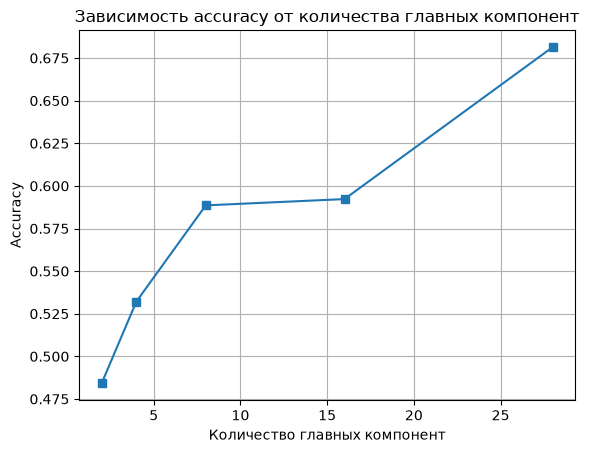

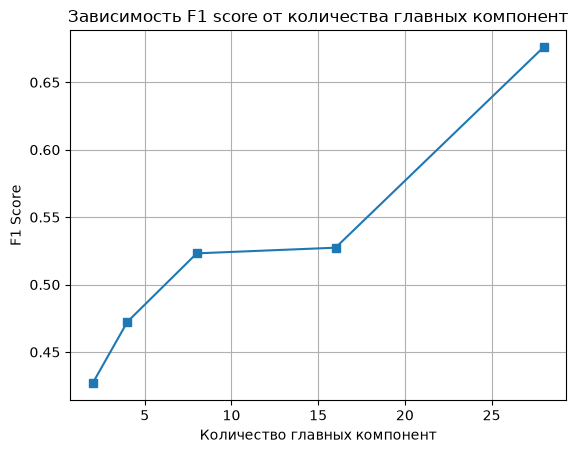

CPU times: user 3min 59s, sys: 1.88 s, total: 4min
Wall time: 1min 9s


In [14]:
%%time
accuracy_dict, f1_score_dict = {}, {}
components_list = [2, 4, 8, 16, 28]
x = components_list
y_accuracy = []
y_f1_score = []

for n_components in components_list:
    accuracy, f1_score = train_pca_i(n_components, X_train, y_train)
    accuracy_dict[n_components] = accuracy
    f1_score_dict[n_components] = f1_score

    # print(f"Accuracy при n_components={n_components} равно {accuracy}")
    # print(f"F1 Score при n_components={n_components} равно {f1_score}")

    y_accuracy.append(accuracy)
    y_f1_score.append(f1_score)

plt.plot(x, y_accuracy, marker='s')    
plt.title('Зависимость accuracy от количества главных компонент')
plt.xlabel('Количество главных компонент')
plt.ylabel('Accuracy')
plt.grid()
plt.show()

plt.plot(x, y_f1_score, marker='s')    
plt.title('Зависимость F1 score от количества главных компонент')
plt.xlabel('Количество главных компонент')
plt.ylabel('F1 Score')
plt.grid()
plt.show()

Обычно, когда решается какая-то высокоразмерная предсказательная задача, где тысячи признаков, функция качества PCA моделей похожа на параболу ветвями вниз в зависимости от количества компонент (для совсем маленьких и больших n_component качество маленькое, при этом есть где-то промежуточное значение).

Как думаете, почему здесь у нас непрерывно растущие графики качества?

Может, изначальные признаки были слишком хороши?

### t-SNE

Напомним, что метод заключается в введении некоторых функций, основанных на расстоянии между признаками, которые измеряют близость объектов. Функций, как вы помните, две, и они заданы в исходном и новом пространствах соотвественно. Далее минимизируем дивергенцию Кульбака-Лейблера по координатaм в новом пространстве

**Задание 6.** Обучите t-sne c `n_components=2` на изначальных данных и визуализируйте результаты с учетом известных классов. 

P.S. если устанете ждать обучения TSNE, или упадет ошибка по типу oom, то можно сократить число объектов в датасете до, например, пары тысяч. Это и следующее задания никак проверяться системой не будут. Вам достаточно повторить упражнение с практики и получить какое-то более адекватное (по сравнению с PCA) изображение классов.

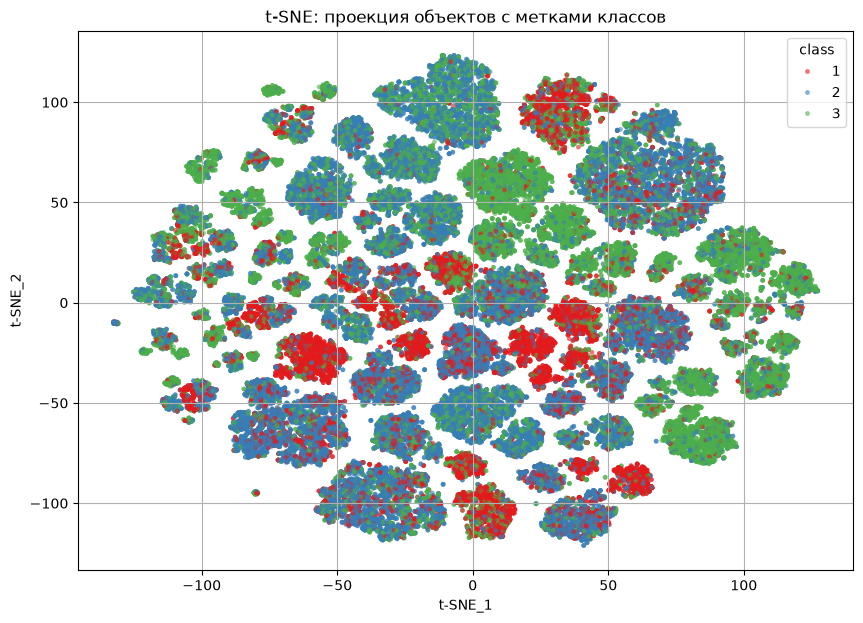

In [ ]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(42)

idx = rng.choice(len(X_train), size=100000, replace=False)

X_small = X_train.iloc[idx]
y_small = y_train.iloc[idx]

X_small_scaled = StandardScaler().fit_transform(X_small)

X_tsne = TSNE(
    n_components=2,
    perplexity=80,
    init='pca',
    learning_rate='auto',
    random_state=42
).fit_transform(X_small_scaled)

tsne_df = pd.DataFrame(X_tsne, columns=['t-SNE_1', 't-SNE_2'])
tsne_df['class'] = y_small.to_numpy()

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=tsne_df,
    x='t-SNE_1',
    y='t-SNE_2',
    hue='class',
    palette='Set1',
    s=12,
    alpha=0.6,
    linewidth=0
)

plt.title('t-SNE: проекция объектов с метками классов')
plt.grid()
plt.show()


**Задание 7.** Обучите t-sne с `n_components=3` на изначальных данных и визуализируйте результаты с учетом известных классов.

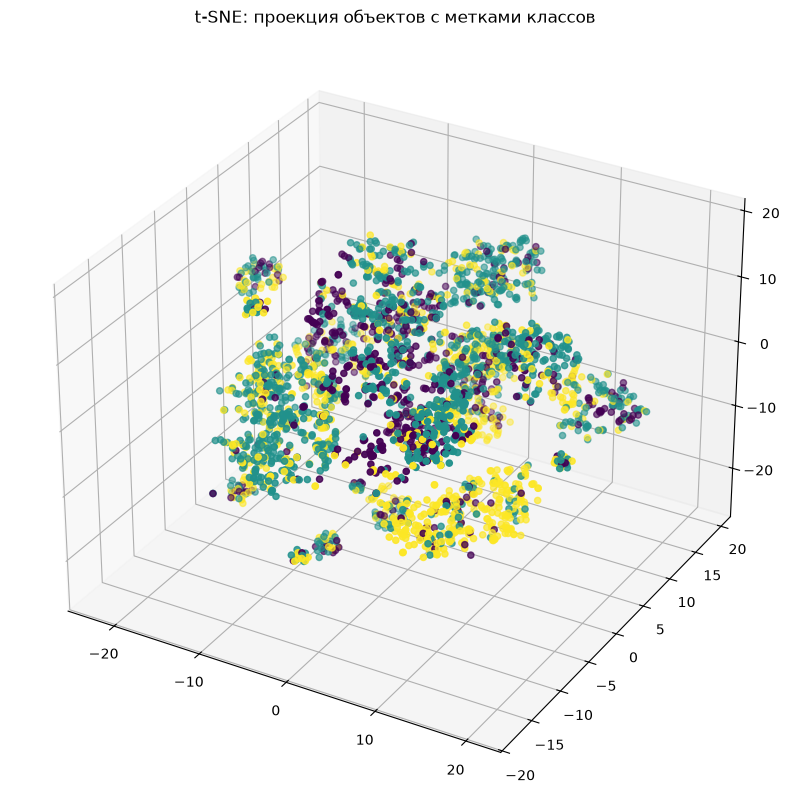

In [42]:
rng = np.random.default_rng(42)
idx = rng.choice(len(X_train), size=3000, replace=False)

X_small = X_train.iloc[idx]
y_small = y_train.iloc[idx]

X_small_scaled = StandardScaler().fit_transform(X_small)

X_tsne = TSNE(
    n_components=3, 
    perplexity=30, 
    init='pca', 
    learning_rate="auto", 
    random_state=42
).fit_transform(X_small_scaled)

tsne_df = pd.DataFrame(X_tsne, columns=['t-SNE_1', 't-SNE_2', 't-SNE_3'])
tsne_df['class'] = y_small.to_numpy()

figure = plt.figure(figsize=(16, 10))
ax = figure.add_subplot(projection='3d')
ax.scatter(tsne_df['t-SNE_1'], tsne_df['t-SNE_2'], tsne_df['t-SNE_3'], c=tsne_df['class'])

plt.title('t-SNE: проекция объектов с метками классов')
plt.grid()
plt.show()


Советуем обрезать датасет до маленького числа объектов (чтобы точки и их группки были хорошо различимы) и поиграться с гиперпараметрами класса Tsne! Обычно такая "игра" может привести к куда более красивым результатам по сравнению с теми, что получены с дефолтными настройками!